# 1.0 Exploratory Data Analysis — Raw Dataset Audit (Pre-Cleaning)

**Project:** Retail E-Commerce — Customer Segmentation & Churn Prediction (`Retail-Ecommerce--CSCP`)  
**Author:** Aman Singh  
**Source File:** `data/raw/online_retail_II.csv`

---

## 1. Raw Dataset Overview

This notebook documents the initial inspection and quality audit of the raw **`online_retail_II.csv`** dataset **before any cleaning or transformation is applied**.

- **Origin:** UCI Machine Learning Repository — *Online Retail II* transactional log.
- **Business Context:** Real transactional records from a UK-based non-store online retailer selling all-occasion giftware. The customer base consists of both individual retail shoppers and B2B wholesale buyers.
- **Granularity:** Each row represents a single product line item within an order (one invoice typically spans multiple rows).
- **Goal of Pre-Cleaning Analysis:** Inspect schema, data types, memory usage, summary distributions, duplicates, missing values, cancellations, non-merchandise codes, and temporal coverage to design a safe, evidence-based cleaning strategy.

### Feature Dictionary (Raw Schema)

| Column Name | Raw Type | Description | Known Raw Characteristics & Risks |
| :--- | :--- | :--- | :--- |
| **`Invoice`** | String (`str`) | 6-digit transaction number | Prefix `'C'` marks a cancellation/credit note; `'A'` marks bad-debt ledger adjustments. |
| **`StockCode`** | String (`str`) | Product SKU identifier | Mostly 5-digit codes (plus letter variants like `85099B`), alongside non-product codes (`POST`, `DOT`, `M`, `BANK CHARGES`). |
| **`Description`** | String (`str`) | Item name / description | Contains missing values, trailing/multiple spaces, and internal warehouse status notes (`check`, `damages`). |
| **`Quantity`** | Integer (`int64`) | Units per transaction line | Negative values occur for customer returns (`C` invoices) and warehouse stock write-offs. |
| **`InvoiceDate`** | String (`str`) | Order timestamp (`YYYY-MM-DD HH:MM:SS`) | Stored as string; needs datetime parsing for chronological and recency calculations. |
| **`Price`** | Float (`float64`) | Unit price in GBP (£) | Contains zero-price warehouse entries and negative bad-debt accounting adjustments. |
| **`Customer ID`** | Float (`float64`) | 5-digit customer identifier | Stored as float because of `NaN` values; missing on guest checkouts and internal adjustments. |
| **`Country`** | String (`str`) | Customer's country | Heavily concentrated in the United Kingdom alongside 42 international markets. |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

raw_path = 'data/raw/online_retail_II.csv' if os.path.exists('data/raw/online_retail_II.csv') else '../data/raw/online_retail_II.csv'
df_raw = pd.read_csv(raw_path)

file_mb = os.path.getsize(raw_path) / (1024 ** 2)
print(f"Pandas: {pd.__version__} | NumPy: {np.__version__}")
print(f"Loaded: {raw_path} ({file_mb:.2f} MB)")
print(f"Shape:  {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

Pandas: 3.0.0 | NumPy: 2.4.2
Loaded: ../data/raw/online_retail_II.csv (91.47 MB)
Shape:  1,067,371 rows x 8 columns


**Observation:**  
The raw file `online_retail_II.csv` (`91.47 MB`) loaded cleanly with **`1,067,371` rows and `8` columns**. Because transactions are recorded at the line-item level, invoice numbers repeat across multiple product rows.

In [2]:
print("--- First 5 Rows ---")
display(df_raw.head(5))

print("\n--- Last 5 Rows ---")
display(df_raw.tail(5))

print("\n--- Random Sample (5 Rows) ---")
display(df_raw.sample(5, random_state=42))

--- First 5 Rows ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085.000,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085.000,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085.000,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085.000,United Kingdom



--- Last 5 Rows ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.100,12680.000,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.150,12680.000,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.150,12680.000,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.950,12680.000,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.000,12680.000,France



--- Random Sample (5 Rows) ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
455941,532657,21314,SMALL GLASS HEART TRINKET POT,12,2010-11-14 11:10:00,2.100,14562.000,United Kingdom
826291,563214,22383,LUNCH BAG SUKI DESIGN,2,2011-08-14 12:56:00,1.650,16370.000,United Kingdom
191636,507597,22561,WOODEN SCHOOL COLOURING SET,12,2010-05-10 13:21:00,1.650,17700.000,United Kingdom
25864,491634,21588,RETRO SPOT GIANT TUBE MATCHES,1,2009-12-11 15:40:00,2.550,17841.000,United Kingdom
73233,496007,85232B,SET/3 RUSSIAN DOLL STACKING TINS,3,2010-01-28 12:32:00,4.950,15203.000,United Kingdom


**Observation:**  
- **Multi-item invoices:** Invoice `489434` spans rows 0–4 across distinct products for Customer `13085.0`; Invoice `581587` (tail) ends with `StockCode = POST` (`POSTAGE`, £18.00), showing that shipping charges appear as line items inside regular invoices.
- **Formatting quirks visible immediately:** `Customer ID` carries a trailing `.0` (`13085.0`), `StockCode` mixes pure digits (`85048`) with suffixed codes (`79323P`, `85232B`), and `Description` contains irregular spacing (e.g., `RETRO SPOT GIANT  TUBE MATCHES` in row `25864`).

In [3]:
df_raw.info(show_counts=True, memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 345.1 MB


**Observation:**  
- **Memory footprint:** The raw DataFrame uses **`345.1 MB`** in memory across `float64` (2), `int64` (1), and `str` (5) columns.
- **Type mismatches for downstream work:**
  1. `InvoiceDate` is stored as `str` and must be converted to `datetime64` before calculating purchase recency or monthly trends.
  2. `Customer ID` is stored as `float64` due to `NaN` entries (`824,364` non-null vs `1,067,371` total rows).
  3. `Invoice` and `StockCode` must remain strings because of `'C'`/`'A'` prefixes and alphanumeric product variants.

In [4]:
num_summary = df_raw[['Quantity', 'Price']].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
display(num_summary)

print("\n--- Extreme Quantity Records (|Quantity| >= 50,000) ---")
display(df_raw[df_raw['Quantity'].abs() >= 50000][['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID']])

,Quantity,Price
count,1067371.000,1067371.000
mean,9.939,4.649
std,172.706,123.553
min,-80995.000,-53594.360
1%,-3.000,0.210
5%,1.000,0.420
25%,1.000,1.250
50%,3.000,2.100
75%,10.000,4.150
95%,30.000,9.950



--- Extreme Quantity Records (|Quantity| >= 50,000) ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.040,12346.000
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.040,12346.000
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.080,16446.000
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.080,16446.000


**Observation:**  
- **`Quantity` distribution:** Typical line items are small — median is **`3`** units and the 75th percentile is **`10`** units (99th percentile is `100`). However, the range stretches from **`-80,995`** to **`+80,995`** (`std = 172.706`).
- **Matched bulk reversals:** Inspecting `|Quantity| >= 50,000` confirms two bulk orders (`74,215` units for Customer `12346` on `2011-01-18` and `80,995` units for Customer `16446` on `2011-12-09`) that were immediately reversed via cancellation invoices (`C541433` and `C581484`) minutes later.
- **`Price` distribution:** Median unit price is **`2.10`** GBP and 75% of records are **`<= 4.15`** GBP (99th percentile `18.00`), while extremes span **`-53,594.36`** to **`38,970.00`** GBP. Zero and negative prices are investigated separately below.

In [5]:
display(df_raw[['Invoice', 'StockCode', 'Description', 'Country']].describe())

# Check description inconsistencies and whitespace
desc_nonnull = df_raw['Description'].dropna()
ws_count = (desc_nonnull != desc_nonnull.str.strip()).sum()
sc_multi_desc = (df_raw.dropna(subset=['Description']).groupby('StockCode')['Description'].nunique() > 1).sum()

# Check non-standard StockCodes (not starting with 5 digits)
sc_str = df_raw['StockCode'].astype(str)
non_std_mask = ~sc_str.str.match(r'^\d{5}[a-zA-Z]*$')

print(f"Descriptions with leading/trailing whitespace: {ws_count:,}")
print(f"StockCodes with >1 distinct Description:       {sc_multi_desc:,}")
print(f"Non-standard StockCode rows:                   {non_std_mask.sum():,} ({non_std_mask.mean()*100:.2f}%)")
print("\n--- Top 10 Non-Standard StockCodes ---")
display(sc_str[non_std_mask].value_counts().head(10).to_frame('Row_Count'))

,Invoice,StockCode,Description,Country
count,1067371,1067371,1062989,1067371
unique,53628,5305,5698,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1350,5829,5918,981330


Descriptions with leading/trailing whitespace: 213,035
StockCodes with >1 distinct Description:       1,232
Non-standard StockCode rows:                   6,094 (0.57%)

--- Top 10 Non-Standard StockCodes ---


,Row_Count
StockCode,
POST,2122
DOT,1446
M,1421
C2,282
D,177
S,104
BANK CHARGES,102
ADJUST,67
AMAZONFEE,43


**Observation:**  
- **High-level cardinality:** There are **`53,628`** unique invoices (`~19.90` rows per invoice), **`5,305`** unique `StockCode` values, **`5,698`** unique `Description` values, and **`43`** countries.
- **Why `Description` count exceeds `StockCode` count:** Exactly **`1,232` StockCodes** appear under multiple descriptions (due to casing/naming changes or manual warehouse remarks), and **`213,035` rows** contain leading or trailing whitespace that inflates string uniqueness.
- **Non-merchandise StockCodes:** **`6,094` rows (`0.57%`)** use non-standard codes such as `POST` (`2,122`), `DOT` (`1,446`), `M` / Manual (`1,421`), `C2` (`282`), `D` / Discount (`177`), `BANK CHARGES` (`102`), `ADJUST` (`67`), and `AMAZONFEE` (`43`). These represent service fees or adjustments rather than physical products.

In [6]:
dup_mask = df_raw.duplicated()
dup_count = dup_mask.sum()
dup_pct = dup_mask.mean() * 100

print(f"Exact Duplicate Rows: {dup_count:,} ({dup_pct:.2f}% of dataset)")

print("\n--- Sample Exact Duplicate Pairs ---")
display(df_raw[df_raw.duplicated(keep=False)].sort_values(by=['Invoice', 'StockCode']).head(6))

Exact Duplicate Rows: 34,335 (3.22% of dataset)

--- Sample Exact Duplicate Pairs ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.950,16329.000,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.950,16329.000,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.750,16329.000,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.750,16329.000,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.750,16329.000,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.750,16329.000,United Kingdom


**Observation:**  
- **`34,335` rows (`3.22%`)** are exact duplicates across all 8 columns (e.g., Invoice `489517`, StockCodes `21491`, `21821`, `21912` logged twice at the exact same timestamp `2009-12-01 11:34:00`).
- **Impact:** Leaving exact duplicates in place artificially inflates line-item frequency and total sales revenue; deduplicating removes `3.22%` of rows cleanly.

,Missing_Count,Missing_Pct,Dtype
Customer ID,243007,22.767,float64
Description,4382,0.411,str
StockCode,0,0.000,str
Invoice,0,0.000,str
Quantity,0,0.000,int64
InvoiceDate,0,0.000,str
Price,0,0.000,float64
Country,0,0.000,str


Guest rows with positive Qty & Price: 236,122 of 243,007
Total Gross Revenue (Qty>0, Price>0): £20,972,968.14
Guest Gross Revenue:                  £3,229,538.96 (15.40%)


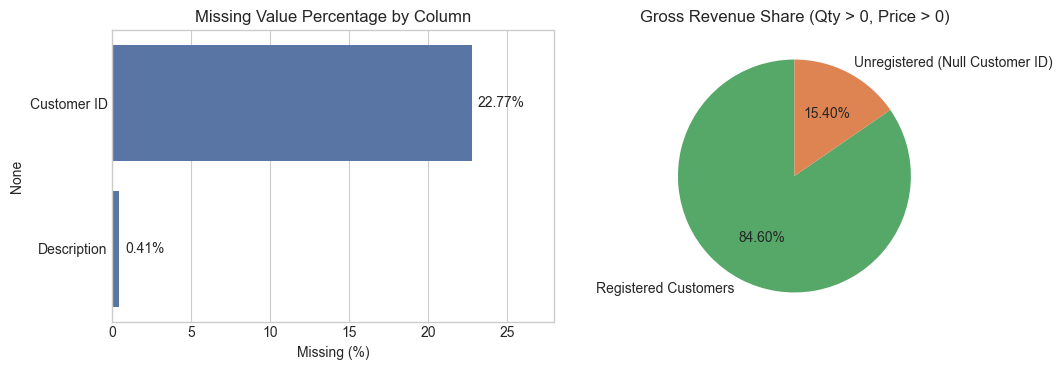

In [7]:
missing_count = df_raw.isnull().sum()
missing_df = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Pct': (missing_count / len(df_raw)) * 100,
    'Dtype': df_raw.dtypes
}).sort_values(by='Missing_Count', ascending=False)
display(missing_df)

# Evaluate commercial value inside missing Customer ID rows
gross_mask = (df_raw['Quantity'] > 0) & (df_raw['Price'] > 0)
guest_mask = df_raw['Customer ID'].isna()
total_gross_rev = (df_raw.loc[gross_mask, 'Quantity'] * df_raw.loc[gross_mask, 'Price']).sum()
guest_gross_rev = (df_raw.loc[gross_mask & guest_mask, 'Quantity'] * df_raw.loc[gross_mask & guest_mask, 'Price']).sum()

print(f"Guest rows with positive Qty & Price: {(gross_mask & guest_mask).sum():,} of {guest_mask.sum():,}")
print(f"Total Gross Revenue (Qty>0, Price>0): £{total_gross_rev:,.2f}")
print(f"Guest Gross Revenue:                  £{guest_gross_rev:,.2f} ({guest_gross_rev/total_gross_rev*100:.2f}%)")

# Visualize missingness and revenue share
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

miss_nonzero = missing_df[missing_df['Missing_Count'] > 0]
sns.barplot(x=miss_nonzero['Missing_Pct'], y=miss_nonzero.index, ax=axes[0], color='#4C72B0')
axes[0].set_title('Missing Value Percentage by Column')
axes[0].set_xlabel('Missing (%)')
for i, v in enumerate(miss_nonzero['Missing_Pct']):
    axes[0].text(v + 0.4, i, f"{v:.2f}%", va='center')
axes[0].set_xlim(0, 28)

rev_labels = ['Registered Customers', 'Unregistered (Null Customer ID)']
rev_vals = [total_gross_rev - guest_gross_rev, guest_gross_rev]
axes[1].pie(rev_vals, labels=rev_labels, autopct='%1.2f%%', startangle=90, colors=['#55A868', '#DD8452'])
axes[1].set_title('Gross Revenue Share (Qty > 0, Price > 0)')

plt.tight_layout()
plt.show()

**Observation:**  
- **Only two columns contain nulls:** `Customer ID` (**`243,007` rows / `22.77%`**) and `Description` (**`4,382` rows / `0.41%`**).
- **Commercial weight of null `Customer ID` rows:** Out of `243,007` missing-ID rows, **`236,122` (`97.17%`)** are valid paid transactions (`Quantity > 0, Price > 0`) representing **£3,229,538.96 (`15.40%`)** of total gross revenue (£20.97M).
- **Cleaning implication:** Simply running `dropna(subset=['Customer ID'])` across the full dataset would discard `22.77%` of all rows and `15.40%` of revenue. In the interim dataset, missing `Customer ID` rows should be retained (e.g., tagged with synthetic guest IDs like `GUEST_<Invoice>`) for accurate sales trend reporting, while registered IDs can be isolated later for customer-level RFM and churn modeling. Missing `Description` (`0.41%`) can be imputed from known `StockCode` mappings.

In [8]:
is_c = df_raw['Invoice'].astype(str).str.startswith('C')
neg_q = df_raw['Quantity'] < 0
zero_q = df_raw['Quantity'] == 0

print(f"Invoices starting with 'C':                {is_c.sum():,}")
print(f"Rows with Quantity < 0:                    {neg_q.sum():,}")
print(f"Rows with Quantity == 0:                   {zero_q.sum():,}")
print(f"'C' invoice AND Quantity < 0:              {(is_c & neg_q).sum():,}")
print(f"'C' invoice WITHOUT Quantity < 0:          {(is_c & ~neg_q).sum():,}")
print(f"Negative Quantity WITHOUT 'C' prefix:      {(~is_c & neg_q).sum():,}")
print(f"  -> Of those, Price == 0:                 {(~is_c & neg_q & (df_raw['Price'] == 0)).sum():,}")
print(f"  -> Of those, Price != 0:                 {(~is_c & neg_q & (df_raw['Price'] != 0)).sum():,}")

print("\n--- Exception: 'C' Invoice with Positive Quantity ---")
display(df_raw[is_c & ~neg_q])

print("\n--- Sample: Negative Quantity Without 'C' Prefix ---")
display(df_raw[~is_c & neg_q].head(5))

Invoices starting with 'C':                19,494
Rows with Quantity < 0:                    22,950
Rows with Quantity == 0:                   0
'C' invoice AND Quantity < 0:              19,493
'C' invoice WITHOUT Quantity < 0:          1
Negative Quantity WITHOUT 'C' prefix:      3,457
  -> Of those, Price == 0:                 3,457
  -> Of those, Price != 0:                 0

--- Exception: 'C' Invoice with Positive Quantity ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.570,NaN,United Kingdom



--- Sample: Negative Quantity Without 'C' Prefix ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.000,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.000,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.000,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.000,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.000,NaN,United Kingdom


**Observation:**  
- **Official cancellations (`'C'` prefix):** There are **`19,494`** cancellation lines; `19,493` carry negative quantities and exactly **`1`** outlier row (`Invoice C496350`, `StockCode M`, `Manual`, `£373.57`) has a positive quantity (`1`).
- **Non-`'C'` negative quantities (`3,457` rows):** Every single one of these **`3,457` rows (`100%`)** has `Price == 0.000` and `Customer ID = NaN`, with warehouse inventory remarks like `85123a mixed` or `short`.
- **Action:** Official `'C'` invoices represent genuine credit notes/returns and should be flagged (`Is_Cancelled = True`), whereas zero-price negative quantity rows are purely internal warehouse write-offs.

In [9]:
zero_price = df_raw[df_raw['Price'] == 0]
neg_price = df_raw[df_raw['Price'] < 0]

print(f"Total rows with Price <= 0:     {len(zero_price) + len(neg_price):,} ({(len(zero_price)+len(neg_price))/len(df_raw)*100:.2f}%)")
print(f"  -> Exactly Price == 0:        {len(zero_price):,}")
print(f"       - With Quantity > 0:     {(zero_price['Quantity'] > 0).sum():,}")
print(f"       - With Quantity < 0:     {(zero_price['Quantity'] < 0).sum():,}")
print(f"       - Registered Customer:   {zero_price['Customer ID'].notna().sum():,}")
print(f"  -> Strictly Price < 0:        {len(neg_price):,}")

print("\n--- Top 10 Descriptions for Price == 0 ---")
display(zero_price['Description'].value_counts().head(10).to_frame('Count'))

print("\n--- All Records with Price < 0 ---")
display(neg_price)

Total rows with Price <= 0:     6,207 (0.58%)
  -> Exactly Price == 0:        6,202
       - With Quantity > 0:     2,745
       - With Quantity < 0:     3,457
       - Registered Customer:   71
  -> Strictly Price < 0:        5

--- Top 10 Descriptions for Price == 0 ---


,Count
Description,
check,162
?,92
damages,84
damaged,81
found,28
missing,27
sold as set on dotcom,20
Damaged,17
adjustment,16



--- All Records with Price < 0 ---


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.360,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.790,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.870,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.060,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.060,NaN,United Kingdom


**Observation:**  
- **`Price == 0` (`6,202` rows):** Split between `2,745` positive-quantity and `3,457` negative-quantity rows. Out of `6,202`, `6,131` lack a `Customer ID` and mostly reflect inventory reconciliation (`check`, `damages`, `damaged`, `found`, `missing`), while only `71` belong to registered customers.
- **`Price < 0` (`5` rows):** Invoices `A506401` through `A563187` all share `StockCode = 'B'` and `Description = 'Adjust bad debt'` with `Customer ID = NaN`. These are accounting write-offs, not retail purchases.
- **Total `Price <= 0` share:** Only **`6,207` rows (`0.58%`)** of the raw dataset.

Rows with Registered Customer ID: 824,364 (77.23%)
Unique Registered Customers:      5,942
Avg Lines per Registered User:    138.7
Customer ID Range:                12346 to 18287
Customers in >1 Country:          13


,Record_Count,Unique_Invoices,Registered_Customers,Record_Share (%)
Country,,,,
United Kingdom,981330,49108,5410,91.939
EIRE,17866,806,5,1.674
Germany,17624,1095,107,1.651
France,14330,746,95,1.343
Netherlands,5140,250,23,0.482
Spain,3811,188,41,0.357
Switzerland,3189,123,22,0.299
Belgium,3123,183,29,0.293
Portugal,2620,124,24,0.245


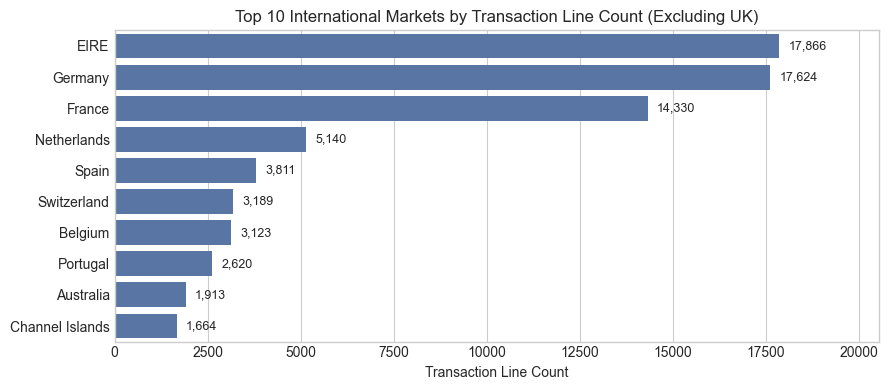

In [10]:
valid_cust = df_raw['Customer ID'].dropna()
cust_countries = df_raw.dropna(subset=['Customer ID']).groupby('Customer ID')['Country'].nunique()

print(f"Rows with Registered Customer ID: {len(valid_cust):,} ({len(valid_cust)/len(df_raw)*100:.2f}%)")
print(f"Unique Registered Customers:      {valid_cust.nunique():,}")
print(f"Avg Lines per Registered User:    {len(valid_cust)/valid_cust.nunique():.1f}")
print(f"Customer ID Range:                {int(valid_cust.min())} to {int(valid_cust.max())}")
print(f"Customers in >1 Country:          {(cust_countries > 1).sum()}")

country_summary = df_raw.groupby('Country').agg(
    Record_Count=('Invoice', 'count'),
    Unique_Invoices=('Invoice', 'nunique'),
    Registered_Customers=('Customer ID', 'nunique')
).sort_values(by='Record_Count', ascending=False)
country_summary['Record_Share (%)'] = (country_summary['Record_Count'] / len(df_raw)) * 100

display(country_summary.head(10))

# Plot Top 10 Non-UK Markets to reveal international demand
intl = country_summary.drop('United Kingdom').head(10)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=intl['Record_Count'], y=intl.index, ax=ax, color='#4C72B0')
ax.set_title('Top 10 International Markets by Transaction Line Count (Excluding UK)')
ax.set_xlabel('Transaction Line Count')
ax.set_ylabel('')
for i, v in enumerate(intl['Record_Count']):
    ax.text(v + 250, i, f"{v:,}", va='center', fontsize=9)
ax.set_xlim(0, intl['Record_Count'].max() * 1.15)
plt.tight_layout()
plt.show()

**Observation:**  
- **Customer base:** **`5,942`** unique registered customers (`12346` to `18287`) account for `824,364` rows (`77.23%`), averaging **`138.7`** lines per customer. **`13`** customers placed orders from more than one country.
- **Geographic concentration:** **`United Kingdom`** dominates with **`981,330` rows (`91.94%`)** and `5,410` registered customers (`91.05%` of all registered IDs).
- **International B2B signal:** `EIRE` ranks second (`17,866` rows / `1.67%`) across **`5` registered customers**, indicating high-volume wholesale accounts, followed by `Germany` (`1.65%`), `France` (`1.34%`), and `Netherlands` (`0.48%`).

Start Timestamp:          2009-12-01 07:45:00
End Timestamp:            2011-12-09 12:50:00
Calendar Span:            738 days
Active Trading Days:      604
Avg Lines per Active Day: 1767.2
Peak Trading Day:         2010-12-06 (7,756 lines)


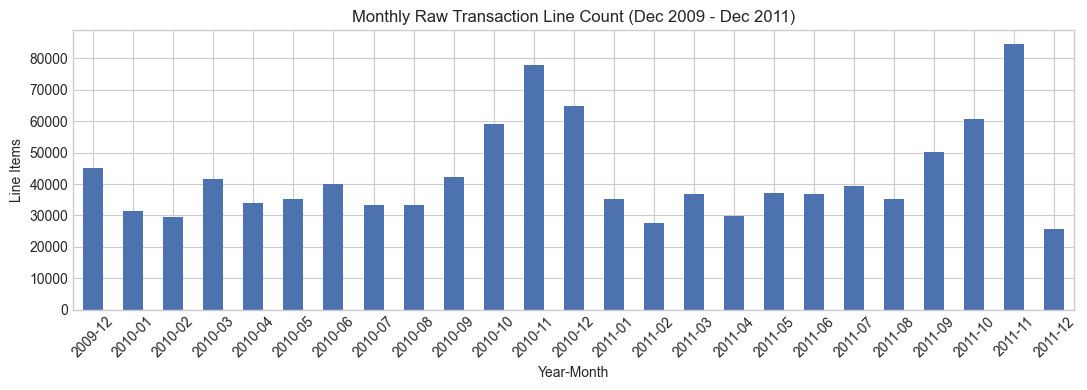

In [11]:
invoice_dates = pd.to_datetime(df_raw['InvoiceDate'])
min_dt, max_dt = invoice_dates.min(), invoice_dates.max()
active_days = invoice_dates.dt.date.nunique()
daily_counts = invoice_dates.dt.date.value_counts().sort_index()

print(f"Start Timestamp:          {min_dt}")
print(f"End Timestamp:            {max_dt}")
print(f"Calendar Span:            {(max_dt - min_dt).days} days")
print(f"Active Trading Days:      {active_days}")
print(f"Avg Lines per Active Day: {daily_counts.mean():.1f}")
print(f"Peak Trading Day:         {daily_counts.idxmax()} ({daily_counts.max():,} lines)")

monthly_counts = invoice_dates.dt.to_period('M').value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 4))
monthly_counts.plot(kind='bar', ax=ax, color='#4C72B0')
ax.set_title('Monthly Raw Transaction Line Count (Dec 2009 - Dec 2011)')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Line Items')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Observation:**  
- **Coverage:** Spans **`738` calendar days** (`2009-12-01 07:45:00` to `2011-12-09 12:50:00`), across **`604` active trading days** averaging **`1,767.2`** line items per day.
- **Seasonality & cutoff:** Activity peaks sharply in Q4 (`November 2010` and `November 2011`), with the busiest single day on **`2010-12-06` (`7,756` lines)**.
- **Partial final month:** `2011-12` is noticeably shorter because recording stops on **9 December 2011**. This partial month should not be compared directly against full 30/31-day months without adjusting for elapsed days.

In [12]:
raw_rows = len(df_raw)
dedup_df = df_raw.drop_duplicates()
dropped_dups = raw_rows - len(dedup_df)

# Simulate removing non-commercial Price <= 0 entries after deduplication
clean_sim = dedup_df[dedup_df['Price'] > 0]
dropped_bad_price = len(dedup_df) - len(clean_sim)

total_dropped = raw_rows - len(clean_sim)
retained_pct = (len(clean_sim) / raw_rows) * 100

summary_impact = pd.DataFrame([
    {'Step': 'Raw Dataset Baseline', 'Rows_Removed': 0, 'Remaining_Rows': raw_rows, 'Pct_of_Raw': 100.00},
    {'Step': '1. Drop Exact Duplicates', 'Rows_Removed': dropped_dups, 'Remaining_Rows': len(dedup_df), 'Pct_of_Raw': len(dedup_df)/raw_rows*100},
    {'Step': '2. Drop Price <= 0 (Adjustments/Errors)', 'Rows_Removed': dropped_bad_price, 'Remaining_Rows': len(clean_sim), 'Pct_of_Raw': retained_pct}
])
display(summary_impact)
print(f"Total Rows Dropped: {total_dropped:,} ({100 - retained_pct:.2f}%) | Retained: {len(clean_sim):,} ({retained_pct:.2f}%)")

,Step,Rows_Removed,Remaining_Rows,Pct_of_Raw
0,Raw Dataset Baseline,0,1067371,100.000
1,1. Drop Exact Duplicates,34335,1033036,96.783
2,2. Drop Price <= 0 (Adjustments/Errors),6019,1027017,96.219


Total Rows Dropped: 40,354 (3.78%) | Retained: 1,027,017 (96.22%)


**Observation & Cleaning Roadmap:**  
Running the exact pre-cleaning simulation confirms that removing exact duplicates (**`34,335` rows / `3.22%`**) and post-deduplication `Price <= 0` accounting/warehouse records (**`6,019` rows / `0.56%`**) removes only **`40,354` rows (`3.78%`)**, retaining **`1,027,017` rows (`96.22%`)** of the raw dataset.

### Planned Preprocessing Steps (for `src/dataset.py` & Next Stage):
1. **Deduplicate:** Drop `34,335` exact duplicate rows.
2. **Filter Non-Commercial Entries:** Drop `6,019` remaining `Price <= 0` records (bad-debt adjustments and zero-price warehouse checks).
3. **Standardize Text & Types:** Strip whitespace from `Description` (`213,035` affected rows), parse `InvoiceDate` to `datetime64`, and format `Customer ID` cleanly.
4. **Impute Missing Values (Zero Additional Drop):** Fill missing `Description` using `StockCode` mode lookup, and tag missing `Customer ID` rows (`GUEST_<Invoice>`) so `15.40%` of gross revenue is preserved for sales analysis while keeping registered accounts clearly separable for RFM and churn modeling.
5. **Flag Returns & Service Items:** Add boolean indicators `Is_Cancelled` (`Invoice.str.startswith('C')`) and `Is_Product_SKU` (standard 5-digit codes vs `6,094` fee/postage rows) plus `TotalAmount = Quantity * Price`.

---

## 4. Post-Cleaning Sales Trends & Behavioral EDA

With raw records cleaned via `src/dataset.py` and exported to `data/interim/online_retail_cleaned.csv.gz` (`1,025,292` rows, `0` duplicates, `0` missing values), we now analyze **monthly revenue seasonality, shopping schedule patterns, top-performing merchandise, and registered vs. guest purchasing behavior**. All figures are saved to `reports/figures/`.

In [13]:
import sys
from pathlib import Path

project_root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.visualization.visualize import (
    plot_monthly_revenue_trend,
    plot_weekday_hourly_sales,
    plot_top_merchandise_products,
    plot_registered_vs_guest_cancellations,
)

cleaned_path = project_root / 'data' / 'interim' / 'online_retail_cleaned.csv.gz'
figures_dir = project_root / 'reports' / 'figures'

df_clean = pd.read_csv(cleaned_path)
print(f"Loaded cleaned interim dataset: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Total Net Revenue: £{df_clean['TotalAmount'].sum():,.2f}")

Loaded cleaned interim dataset: 1,025,292 rows x 22 columns
Total Net Revenue: £19,349,064.69


**Observation:**  
The cleaned compressed dataset (`online_retail_cleaned.csv.gz`) loads directly into Pandas with **`1,025,292` rows and `22` columns**, capturing **£19,349,064.69** in total net revenue.

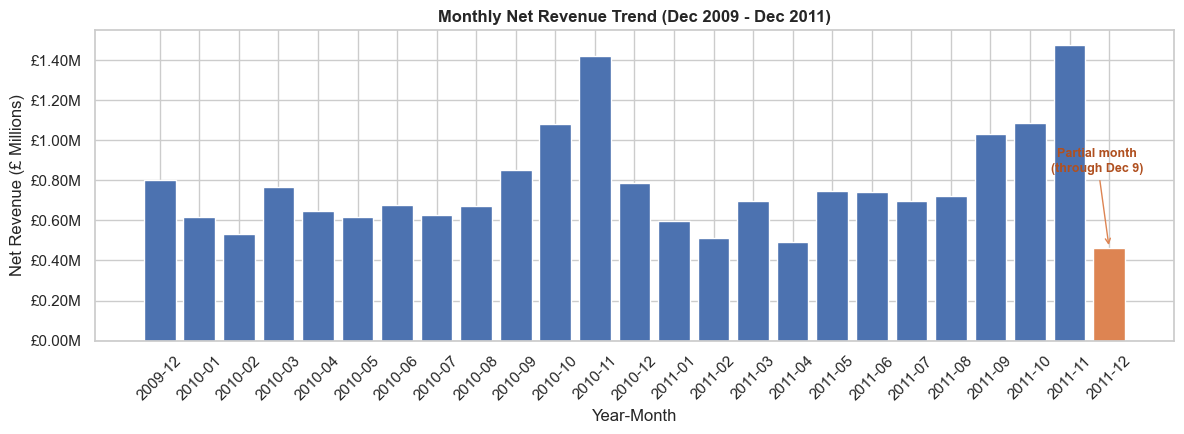

--- Top 3 Months by Net Revenue ---


,YearMonth,Is_Partial_Month,Net_Revenue,Unique_Invoices
23,2011-11,False,1473673.420,3180
11,2010-11,False,1417621.720,3300
22,2011-10,False,1087853.720,2350


--- Bottom 3 Months by Net Revenue ---


,YearMonth,Is_Partial_Month,Net_Revenue,Unique_Invoices
24,2011-12,True,463194.690,958
16,2011-04,False,491345.740,1464
14,2011-02,False,512563.540,1292


In [14]:
monthly_df = plot_monthly_revenue_trend(
    df_clean, save_path=figures_dir / 'monthly_revenue_trend.png'
)
print("--- Top 3 Months by Net Revenue ---")
display(monthly_df.nlargest(3, 'Net_Revenue'))
print("--- Bottom 3 Months by Net Revenue ---")
display(monthly_df.nsmallest(3, 'Net_Revenue'))

**Observation (Monthly Revenue & Seasonality):**  
- **Strong Q4 Holiday Peaks:** November is consistently the highest-revenue month across both years — **`2011-11` (£1,473,673.42, `3,180` invoices)** and **`2010-11` (£1,417,621.72, `3,300` invoices)**, followed by **`2011-10` (£1,087,853.72)**.
- **Partial Month Caveat:** **`2011-12` (£463,194.69)** appears lowest solely because transaction logs end on **9 December 2011** (`Is_Partial_Month = True`). Excluding Dec 2011, **`2011-04` (£491,345.74)** and **`2011-02` (£512,563.54)** mark the quietest full months.

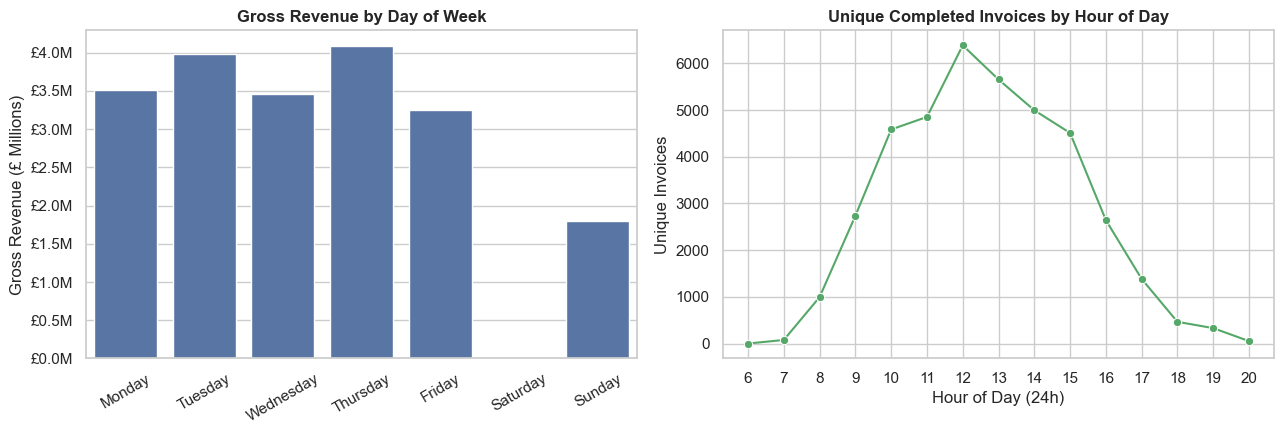

--- Gross Revenue by Day of Week ---


,Gross_Revenue_GBP
DayOfWeek,
Monday,3514015.540
Tuesday,3978698.710
Wednesday,3461889.330
Thursday,4086279.920
Friday,3246337.160
Saturday,9803.050
Sunday,1797402.650



--- Top 5 Peak Ordering Hours ---


,Unique_Invoices
Hour,
12,6387
13,5656
14,4997
11,4854
10,4585


In [15]:
dow_rev, hour_orders = plot_weekday_hourly_sales(
    df_clean, save_path=figures_dir / 'weekday_hourly_sales.png'
)
print("--- Gross Revenue by Day of Week ---")
display(dow_rev.to_frame('Gross_Revenue_GBP'))
print("\n--- Top 5 Peak Ordering Hours ---")
display(hour_orders.nlargest(5).to_frame('Unique_Invoices'))

**Observation (Operating Schedule & Hourly Activity):**  
- **Weekday B2B Profile:** **`Thursday` (£4,086,279.92)** and **`Tuesday` (£3,978,698.71)** generate the highest gross revenue, while **`Saturday` drops to just £9,803.05** across the entire 2-year window before rebounding on **`Sunday` (£1,797,402.65)**. This near-zero Saturday volume reflects B2B wholesale ordering desks and fulfillment operations pausing on Saturdays.
- **Peak Ordering Window:** Completed order volume peaks squarely around midday between **10:00 AM and 2:00 PM**, reaching its maximum at **12:00 PM (`6,387` unique invoices)**.

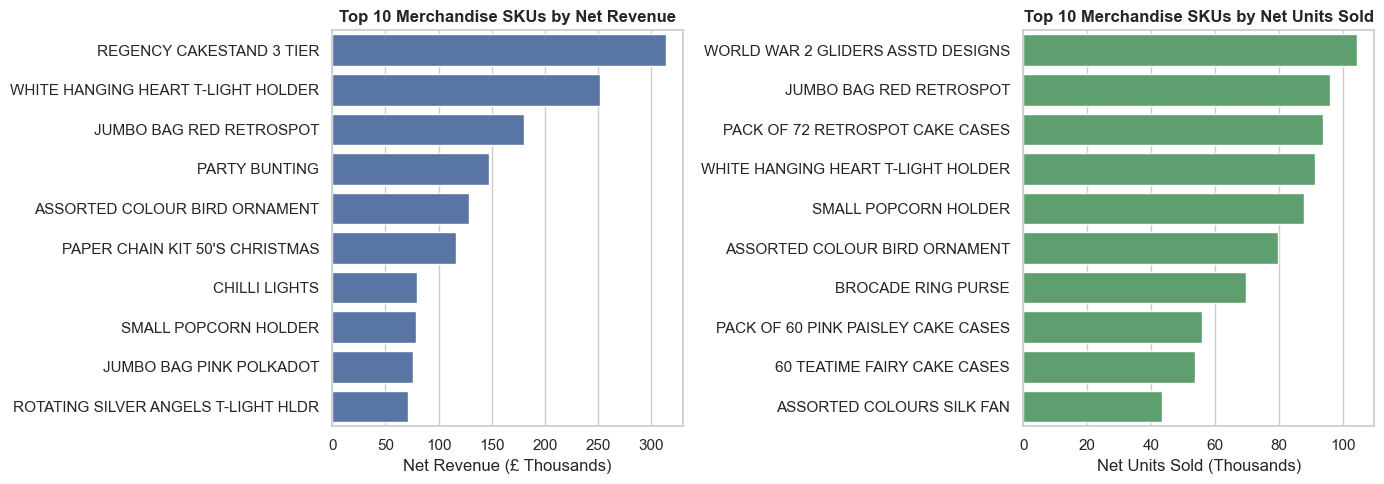

,StockCode,Description,Net_Revenue,Net_Units
1640,22423,REGENCY CAKESTAND 3 TIER,314045.020,25028
4165,85123A,WHITE HANGING HEART T-LIGHT HOLDER,251781.630,91082
4143,85099B,JUMBO BAG RED RETROSPOT,180512.160,95963
3137,47566,PARTY BUNTING,147079.730,27915
3903,84879,ASSORTED COLOUR BIRD ORNAMENT,128550.420,79571


In [16]:
top_products = plot_top_merchandise_products(
    df_clean, top_n=10, save_path=figures_dir / 'top_10_merchandise_products.png'
)
display(top_products.head(5))

**Observation (Top Merchandise Drivers):**  
- Restricting to physical `Item_Category == 'Merchandise'` isolates genuine product winners from shipping fees (`POST`, `DOT`):
  - **Highest Revenue SKU:** **`REGENCY CAKESTAND 3 TIER` (`22423`)** leads with **£314,045.02** across `25,028` net units, followed by **`WHITE HANGING HEART T-LIGHT HOLDER` (`85123A`, £251,781.63)** and **`JUMBO BAG RED RETROSPOT` (`85099B`, £180,512.16)**.
  - **Volume vs. Margin Contrast:** `JUMBO BAG RED RETROSPOT` (`95,963` units) and `WHITE HANGING HEART T-LIGHT HOLDER` (`91,082` units) drive the largest unit volume, whereas higher-ticket items like the Regency Cakestand lead total revenue.

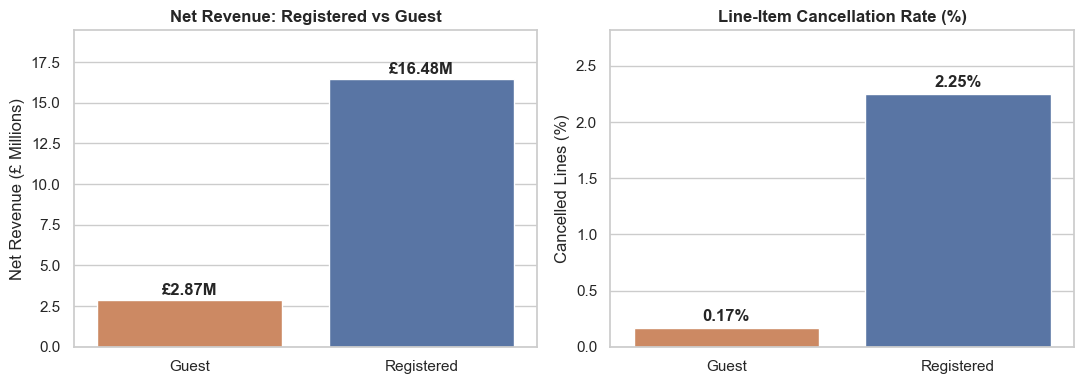

,Cohort,Total_Lines,Unique_Invoices,Net_Revenue,Revenue_Share_Pct,Cancelled_Lines,Cancel_Rate_Pct
0,Guest,228688,3125,2869293.320,14.829,384,0.168
1,Registered,796604,44254,16479771.370,85.171,17938,2.252


In [17]:
cohort_df = plot_registered_vs_guest_cancellations(
    df_clean, save_path=figures_dir / 'registered_vs_guest_cancellations.png'
)
cohort_df['Revenue_Share_Pct'] = (cohort_df['Net_Revenue'] / cohort_df['Net_Revenue'].sum()) * 100
display(cohort_df[['Cohort', 'Total_Lines', 'Unique_Invoices', 'Net_Revenue', 'Revenue_Share_Pct', 'Cancelled_Lines', 'Cancel_Rate_Pct']])

**Observation (Registered vs. Guest Cohorts & Cancellation Risk):**  
- **Revenue Contribution:** Registered accounts (`44,254` invoices) generate **£16,479,771.37 (`85.17%`)** of net revenue, while unregistered guest checkouts (`3,125` invoices) contribute **£2,869,293.32 (`14.83%`)** — confirming why retaining guest records in the interim dataset is vital for accurate sales reporting.
- **Cancellation Behavior:** Registered users exhibit a **`2.25%`** line-item cancellation rate (`17,938` lines), more than 13x higher than guest checkouts (**`0.17%`**, `384` lines), reflecting bulk wholesale order adjustments among repeat B2B accounts.
- **Next Phase (Week 2):** Filter `Is_Registered == True` and `Item_Category == 'Merchandise'` (with net signed calculations) to engineer customer-level **Recency, Frequency, and Monetary (RFM)** features in `src/features.py` and segment cohorts via K-Means clustering.